> **언어 전환 & 바로가기**: **🇰🇷 한국어 ( 현재 )** · [🇺🇸 English Version](./stage0_overview_walkthrough_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../methodology/METHODOLOGY_KO.md) ｜ [노트북 전체 인덱스 (README)](./README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=overview)
>
> **전체 라이프사이클 네비게이션**: **[▶ 0. 전체 흐름 개요](./stage0_overview_walkthrough.ipynb)** → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# 0. 전체 흐름 초기 화면 — 8단계 엔지니어링 파이프라인 & 5-Stage 에이전틱 온톨로지 워크스루
## 준비 → 분석 → 파싱 → 통합 → 구축 → 에이전트 구축 → 답변 → 검증 (BigQuery Property Graph · ISO GQL · Gemini 3.8 Flash)

이 초기 노트북은 **Agentic Ontology Starter Pack v2.0**의 전체 엔지니어링 방법론을 처음부터 끝까지 한눈에 파악하고 실행하는 **마스터 진입 화면**입니다. 단순 데이터 조회에 그치지 않고, **원시 데이터 준비(Phase 1) → 탐색·CQ 설계(Phase 2) → 비정형 문서 파싱·SHA-256 해시 앵커링(Phase 3) → 3-Layer Wiki 및 시맨틱 규칙 통합(Phase 4) → BigQuery/Spanner 물리 프로퍼티 그래프 구축(Phase 5) → 8종 MCP 서버 및 2-Pass 에이전트 구축(Phase 6) → 실시간 ISO GQL 생성 및 근거 기반 답변(Phase 7) → 4-Tier 리니지 및 50회 경계값 벤치마크 검증(Phase 8)**의 전 과정을 중간 데이터·테이블 구조·그래프 설계 도식과 함께 조화롭게 확인합니다.

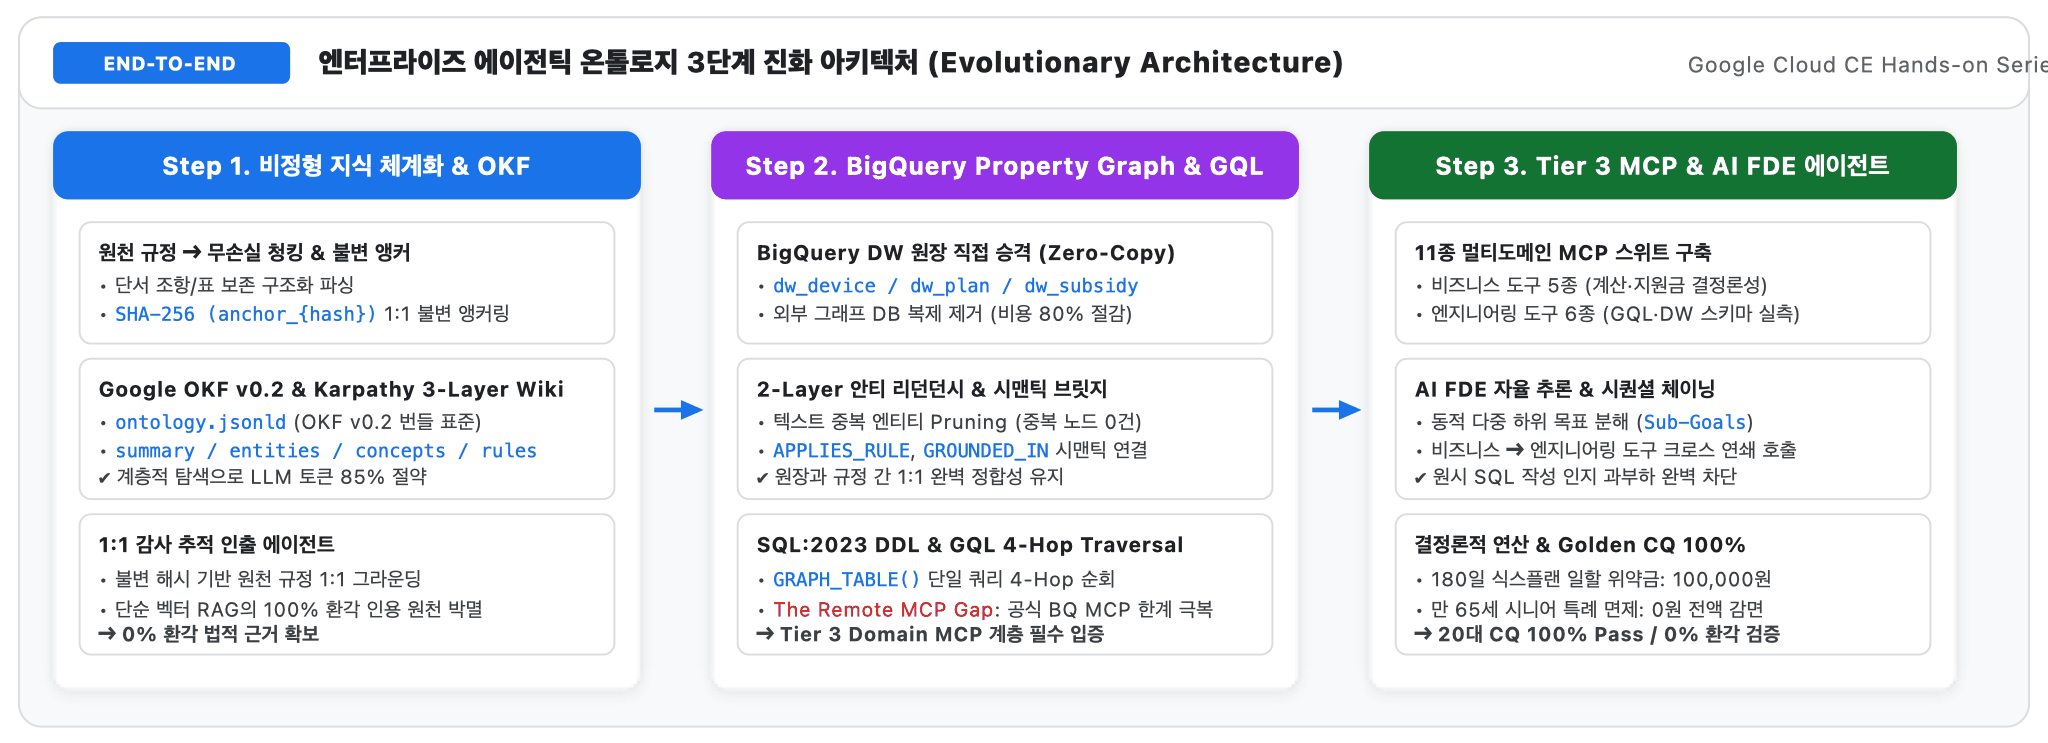

### 전체 8단계 엔지니어링 흐름 및 한/영 노트북 네비게이션 맵

| 엔지니어링 단계 (8-Phase) | 정본 Stage (Step) | 핵심 구현 모듈 및 MCP 도구 | 중간 확인 데이터 · 테이블 · 그래프 도식 | 한글 노트북 (KO) | 영문 노트북 (EN) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. 준비 (Prepare)**<br>**2. 분석 (Analyze)** | **Stage 1**<br>(`Step 1.1`–`1.2`) | `terraform/bigquery.tf`<br>`mcp_stage1_asset_discovery`<br>`H.check_cq_sql()` | 원시 CSV/MD 인벤토리, 10개 테이블 스키마 설계도, 비식별 약정 원장, 지원금 히트맵, Golden CQ 5종 SQL 검증 | [`stage1_ko`](./stage1_asset_and_cq_ko.ipynb) | [`stage1_en`](./stage1_asset_and_cq_en.ipynb) |
| **3. 파싱 (Parse)**<br>**4. 통합 (Integrate)** | **Stage 2**<br>(`Step 2.1`–`2.2`) | `pipeline/ingest.py`<br>`mcp_stage2_wiki_and_semantic`<br>`H.propose_triples()` | `DOC_CHUNK` 정규식 파싱 & SHA-256 해시 앵커 비교표, 3-Layer Wiki 4종, Gemini 트리플 추출, 시맨틱 그래프 도식 | [`stage2_ko`](./stage2_wiki_and_semantic_graph_ko.ipynb) | [`stage2_en`](./stage2_wiki_and_semantic_graph_en.ipynb) |
| **5. 구축 (Build Graph)** | **Stage 3**<br>(`Step 3.1`–`3.2`) | `pipeline/graph_builder.py`<br>`mcp_stage3_property_graph`<br>`H.nl2gql()` | 6 Node × 4 Edge 메타모델 설계도, BigQuery/Spanner Graph DDL, 전체 토폴로지 & 1~2홉 서브그래프, ISO GQL & NL2GQL | [`stage3_ko`](./stage3_property_graph_bigquery_spanner_ko.ipynb) | [`stage3_en`](./stage3_property_graph_bigquery_spanner_en.ipynb) |
| **6. 에이전트 구축 (Agent)**<br>**7. 답변 (Answer)** | **Stage 4**<br>(`Step 4.1`–`4.2`) | `src/agent/mcp_server.py`<br>`src/agent/reasoning_engine.py`<br>`mcp_stage4_agent_orchestration` | 2-Pass 에이전트 오케스트레이션 설계도, 8종 MCP 카탈로그, 슬롯 파싱, 180일 위약금 곡선, Golden CQ & 경계 답변 | [`stage4_ko`](./stage4_agent_and_mcp_execution_ko.ipynb) | [`stage4_en`](./stage4_agent_and_mcp_execution_en.ipynb) |
| **8. 검증 (Verify & Gate)** | **Stage 5**<br>(`Step 5.1`–`5.2`) | `pipeline/validator.py`<br>`mcp_stage5_lineage_and_eval`<br>`H.recheck_cq()` | 4-Tier 데이터 리니지 테이블 & 멀티파타이트 그래프, Golden CQ 5종 실시간 재검증, Boundary 50회 평가 & Gate 1~5 판정 | [`stage5_ko`](./stage5_lineage_and_evaluation_ko.ipynb) | [`stage5_en`](./stage5_lineage_and_evaluation_en.ipynb) |

### 조직 성숙도별 3-Track 도입 가이드 (`config/starter_config.json`)

| 트랙 (Track) | 활성 Stage | 물리 그래프 엔진 | 적용 목적 및 권장 시나리오 |
| :--- | :--- | :--- | :--- |
| **Track 1 · Lite** | `Stage 1 → Stage 2 → Stage 4` | `none` | 비정형 정책 문서 위키(3-Layer LLM-Wiki)와 도메인 규칙 테이블만으로 빠르게 에이전트를 기동할 때 |
| **Track 2 · Standard** | `Stage 1 → Stage 2 → Stage 3 → Stage 4` | `bigquery` / `spanner` | 정형 DW 원장 4종과 비정형 규칙을 Zero-ETL Property Graph로 결합해 다중 홉 ISO GQL 추론을 수행할 때 |
| **Track 3 · Full-Stack** | `Stage 1 → Stage 2 → Stage 3 → Stage 4 → Stage 5` | `bigquery` | 4-Tier 데이터 리니지, Golden CQ 5건(100%), 경계값 10건×5회(50회) 벤치마크 및 Cloud Run 배포 게이트까지 운영할 때 |


In [1]:
%load_ext bigframes
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
server = DomainMcpServer()
agent = AiFdeAgentEngine()
H.setup("ko")


,project,dataset,location,graph,model,lang
0,seanjung-poc,starter_ontology_dw,asia-northeast3,STARTER_ONTOLOGY_GRAPH,gemini-3.8-flash,ko


### 1. [전체 아키텍처 도식] 8단계 엔지니어링 파이프라인 및 10개 테이블 스키마 블루프린트


findfont: Failed to find font weight bold for AppleGothic, now using 400.


findfont: Failed to find font weight bold for AppleGothic, now using 400.


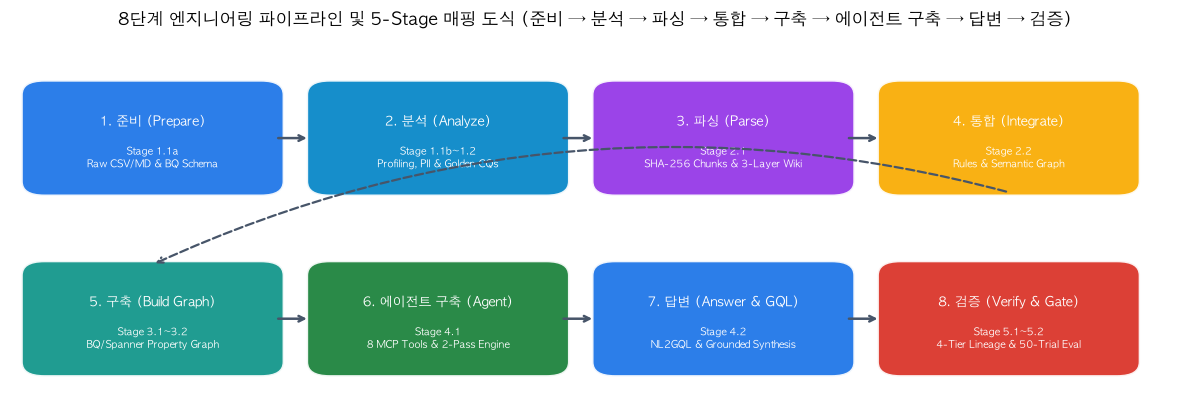

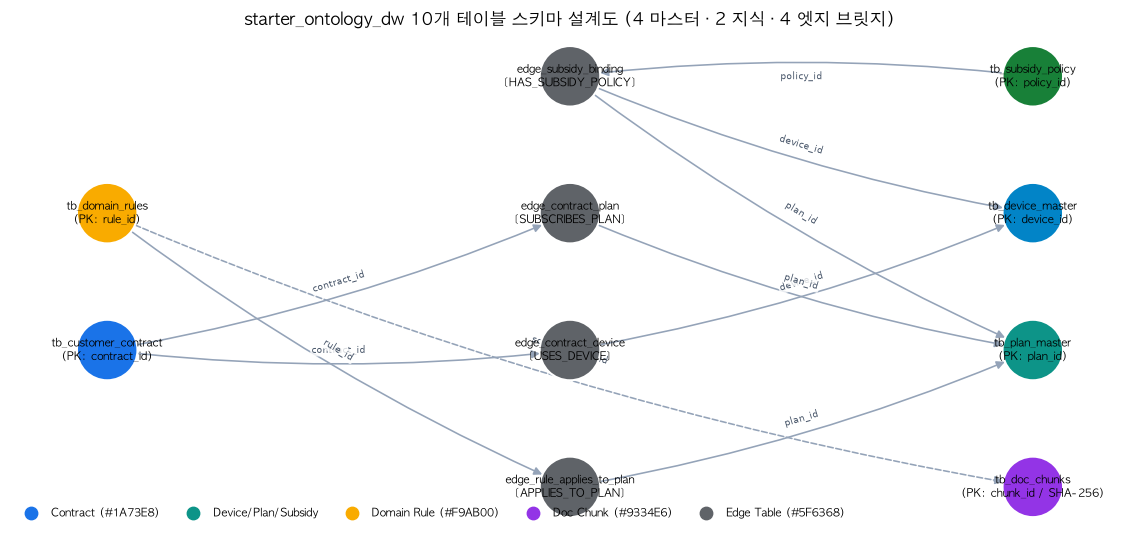

In [2]:
H.draw_eight_phase_flow()
H.draw_table_er_blueprint()


### 2. [Phase 1~2 · Stage 1: 준비 & 분석] 원시 입력 자산 인벤토리 확인 및 BigQuery 10개 테이블 프로파일링 (`mcp_stage1_asset_discovery` + `%%bqsql`)


In [3]:
H.show(H.raw_inputs_inventory())
res_s1 = server.execute_tool("mcp_stage1_asset_discovery")
H.show_tool(res_s1)


,input_file,asset_type,volume,key_contents
0,01_guides/sample_policy_guide.md,Unstructured Policy Guide,"16 lines (1,363 chars)","DOC_CHUNK_001~003 (Subsidy Cap, 180d Retention, Prorated Formula)"
1,01_guides/sample_welfare_exemption_guide.md,Unstructured Policy Guide,"11 lines (1,252 chars)","DOC_CHUNK_004~005 (Senior/Welfare Exemption, 24M TCO Rule)"
2,03_tables/devices.csv,Master CSV (Structured),4 rows,"device_id, pet_name, storage, manufacturer, factory_price, release_date"
3,03_tables/plans.csv,Master CSV (Structured),6 rows,"plan_id, plan_name, tier_category, monthly_fee, min_maintenance_days, selective_discou..."
4,03_tables/subsidies.csv,Master CSV (Structured),5 rows,"policy_id, device_id, plan_id, basic_subsidy, distribution_subsidy, mandatory_retentio..."
5,03_tables/customer_contracts.csv,Master CSV (Structured),6 rows,"contract_id, customer_id (CUST_DEMO_*), device_id, plan_id, contract_type, elapsed_day..."
6,03_tables/domain_rules.csv,Semantic Rule CSV,4 rows,"rule_id, rule_name, rule_category, condition_expr, formula_expr, source_chunk_id"
7,03_tables/rule_plan_edges.csv,Semantic Bridge CSV,12 rows,"edge_id, rule_id, plan_id, source_chunk_id, relation_label_ko"
8,04_cq/golden_competency_questions.json,Golden CQ Benchmark Spec,5 items,"5 Golden CQs with expected_math, verification_sql, grounded_chunk"
9,04_cq/boundary_cases.json,Boundary Benchmark Spec,10 items,"10 Boundary Cases with root_cause_code, accept_answer_status"


**`mcp_stage1_asset_discovery`** · status `SUCCESS` · steps `profile_tables, scan_guides, prune_noise, tag_pii_governance` · BigQuery jobs 2 (2,516 ms)

BigQuery `seanjung-poc.starter_ontology_dw` 테이블 10개, 총 59행 실측 · 비식별 규칙 위반 고객 ID 0건

- `job_ibbqkHLG4jCOtGMZ5IAOpuuBZAb7`
- `job_Y-0vV9qqktbz8kSw7yAKHz7Ik4gl`

In [4]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN '3_edge_bridge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN '2_knowledge_wiki'
       ELSE '1_structured_master' END AS table_role
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY table_role, table_id


,table_id,row_count,size_bytes,table_role
0,tb_customer_contract,6,856,1_structured_master
1,tb_device_master,4,292,1_structured_master
2,tb_plan_master,6,423,1_structured_master
3,tb_subsidy_policy,5,382,1_structured_master
4,tb_doc_chunks,5,2784,2_knowledge_wiki
5,tb_domain_rules,4,1858,2_knowledge_wiki
6,edge_contract_device,6,368,3_edge_bridge
7,edge_contract_plan,6,379,3_edge_bridge
8,edge_rule_applies_to_plan,12,1450,3_edge_bridge
9,edge_subsidy_binding,5,342,3_edge_bridge


,table_id,row_count,size_bytes,table_role
0,tb_customer_contract,6,856,1_structured_master
1,tb_device_master,4,292,1_structured_master
2,tb_plan_master,6,423,1_structured_master
3,tb_subsidy_policy,5,382,1_structured_master
4,tb_doc_chunks,5,2784,2_knowledge_wiki
5,tb_domain_rules,4,1858,2_knowledge_wiki
6,edge_contract_device,6,368,3_edge_bridge
7,edge_contract_plan,6,379,3_edge_bridge
8,edge_rule_applies_to_plan,12,1450,3_edge_bridge
9,edge_subsidy_binding,5,342,3_edge_bridge


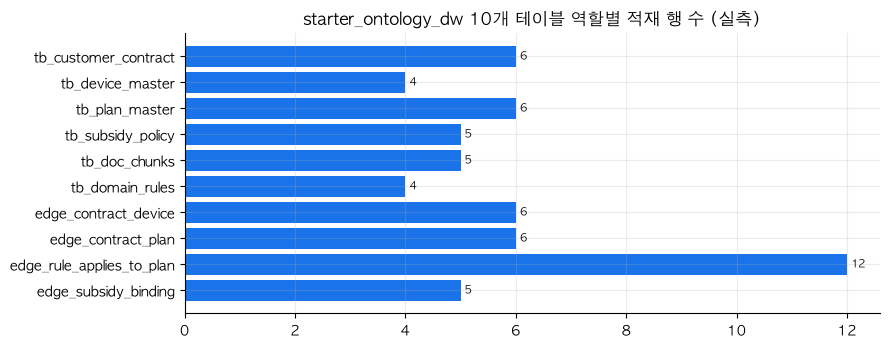

In [5]:
H.show(df_tables)
H.bar(df_tables, "table_id", "row_count", H.t("starter_ontology_dw 10개 테이블 역할별 적재 행 수 (실측)", "Row Count across 10 Tables in starter_ontology_dw"), horizontal=True)


### 3. [Phase 3~4 · Stage 2: 파싱 & 통합] 비정형 가이드 SHA-256 청킹 · 3-Layer Wiki 컴파일 · 시맨틱 온톨로지 그래프 설계 도식


,chunk_id,source_file,section_title,chars,computed_anchor,bq_stored_anchor,sha256_match,excerpt
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,222,anchor_a52e1a72869f,anchor_a52e1a72869f,True,## 1. General Principles
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),467,anchor_3003b683cea0,anchor_3003b683cea0,True,## 2. 180-Day Baseline Plan Commitment Rule
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,444,anchor_47971ec8e4d8,anchor_47971ec8e4d8,True,## 3. Penalty Settlement Computation Formula
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,583,anchor_269d9c42e05c,anchor_269d9c42e05c,True,## 4. Statutory Penalty Exemption Clauses (위약금 면제 특례 규정)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,472,anchor_4fbaf9c5cba8,anchor_4fbaf9c5cba8,True,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPA


,wiki_layer,file,lines,gcs_object_uri,role
0,Layer 1 (Executive Summary),summary.md,8,gs://seanjung-poc-starter-ontology/ontology/summary.md,"Domain scope, OKF v0.2 framework, total chunks & BigQuery tables"
1,Layer 2 (Core Entities),entities.md,31,gs://seanjung-poc-starter-ontology/ontology/entities.md,"Compiled directory of contracts, devices, plans, and subsidy policies"
2,Layer 3 (Semantic Concepts),concepts.md,7,gs://seanjung-poc-starter-ontology/ontology/concepts.md,"Entity=Node, Concept=Edge relationship definitions (4 edge types)"
3,Layer 3 (Codified Rules),rules.md,22,gs://seanjung-poc-starter-ontology/ontology/rules.md,"Deterministic business rules with condition_expr, formula_expr & chunk anchors"


**`mcp_stage2_wiki_and_semantic`** · status `SUCCESS` · steps `compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges` · BigQuery jobs 1 (575 ms)

GCS 객체 8개 · 청크/규칙 조인 5행

- `job_OYm-7i3odprNSe8Mi1ThKAf03RvP`

,chunk_id,source_file,section_title,anchor,trust_tier,rule_id,rule_name,formula_expr
0,DOC_CHUNK_001,sample_policy_guide.md,Overview & Scope,anchor_a52e1a72869f,GOLDEN_VERIFIED,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...
1,DOC_CHUNK_002,sample_policy_guide.md,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,GOLDEN_VERIFIED,NaN,NaN,NaN
2,DOC_CHUNK_003,sample_policy_guide.md,Penalty Math Formula,anchor_47971ec8e4d8,GOLDEN_VERIFIED,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...
3,DOC_CHUNK_004,sample_welfare_exemption_guide.md,Statutory Penalty Exemptions,anchor_269d9c42e05c,GOLDEN_VERIFIED,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)
4,DOC_CHUNK_005,sample_welfare_exemption_guide.md,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,GOLDEN_VERIFIED,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...


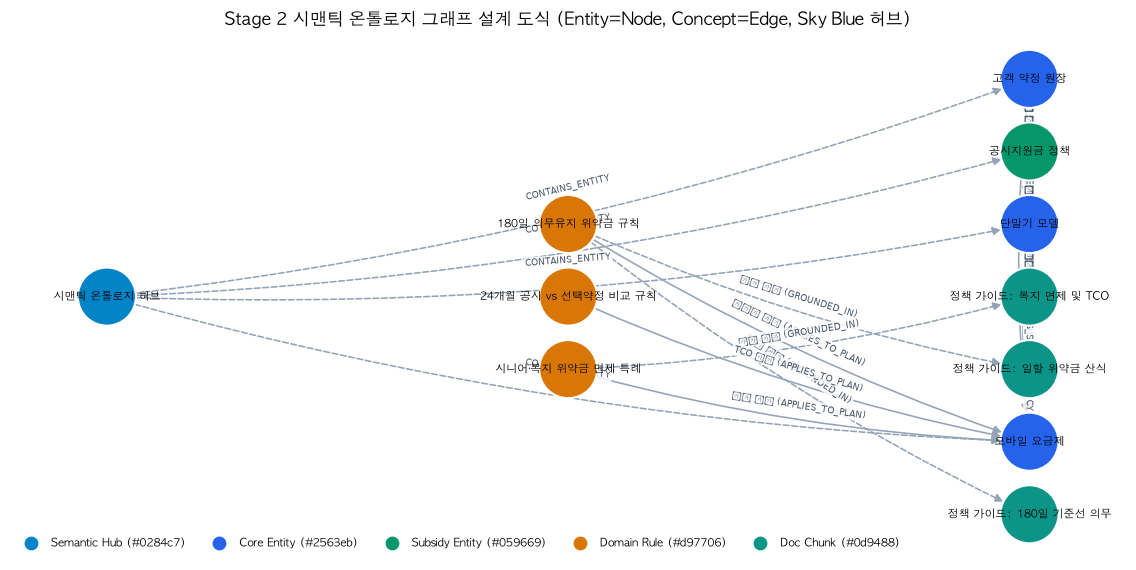

In [6]:
H.show(H.parse_guides_live_demo())
df_wiki, manifest = H.wiki_compilation_summary()
H.show(df_wiki)
res_s2 = server.execute_tool("mcp_stage2_wiki_and_semantic")
H.show_tool(res_s2, "anchored_chunks")
H.draw_semantic_design_graph()


### 4. [Phase 5 · Stage 3: 물리 그래프 구축] `STARTER_ONTOLOGY_GRAPH` 메타모델 검증 및 전체 인스턴스 토폴로지 (`%%bqsql` + ISO GQL)


**`mcp_stage3_property_graph`** · status `SUCCESS` · steps `promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates` · BigQuery jobs 2 (1,328 ms)

노드 테이블 중복 키 0건 · GQL 경로(Device→Plan←Rule) 10개

- `job_gxMJfgIGenpRj7dP9J97bd52dchN`
- `job_cRCCt0L2pdQhO3h1qhZjL694VzsG`

,node_table,row_count,duplicate_keys
0,tb_device_master,4,0
1,tb_plan_master,6,0
2,tb_subsidy_policy,5,0
3,tb_customer_contract,6,0
4,tb_doc_chunks,5,0
5,tb_domain_rules,4,0


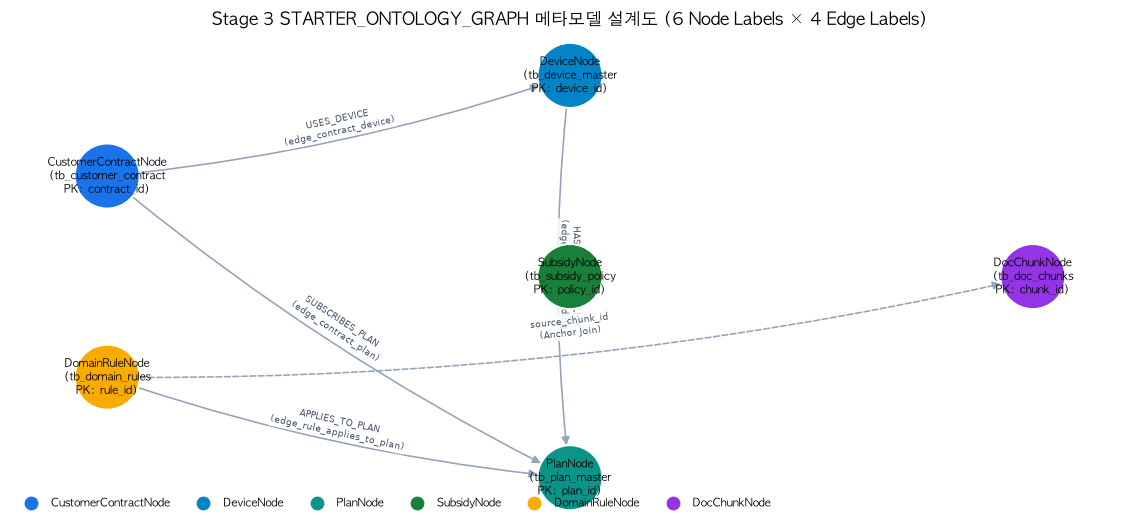

In [7]:
res_s3 = server.execute_tool("mcp_stage3_property_graph")
H.show_tool(res_s3, "node_tables")
H.draw_property_graph_metamodel()


In [8]:
%%bqsql df_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


,path
0,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
3,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
4,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
5,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
6,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
7,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
8,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
9,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."


**실측 추출된 물리 그래프 노드 `19`개 · 엣지 `29`개**

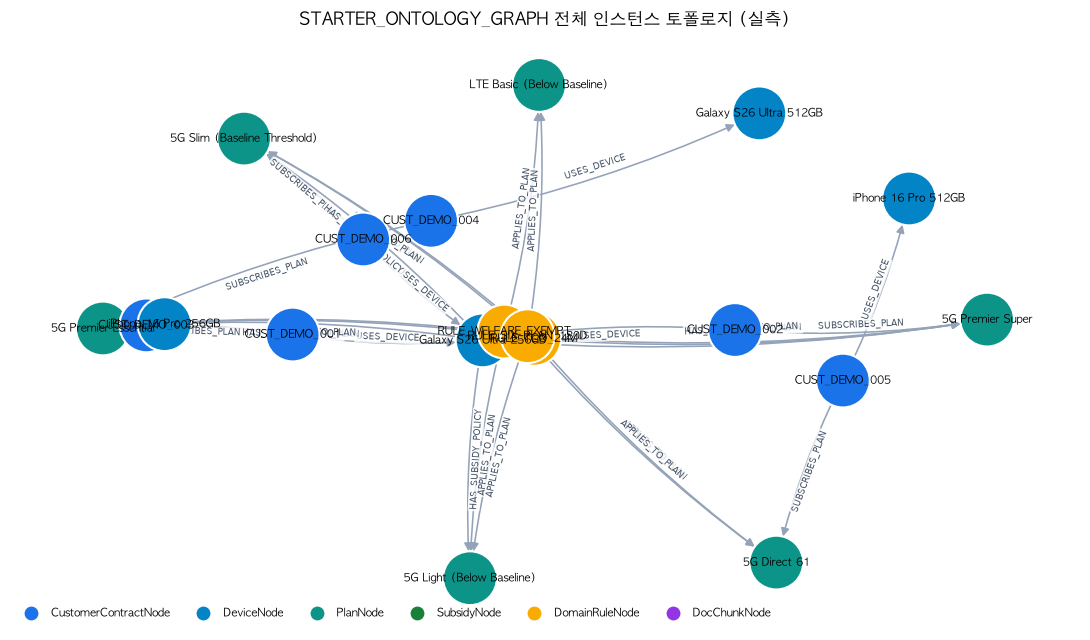

In [9]:
nodes, edges = H.paths_to_graph(H.pdf(df_paths)["path"])
H.md(H.t(f"**실측 추출된 물리 그래프 노드 `{len(nodes)}`개 · 엣지 `{len(edges)}`개**", f"**Extracted physical graph nodes: `{len(nodes)}` · edges: `{len(edges)}`**"))
H.draw_graph(nodes, edges, H.t("STARTER_ONTOLOGY_GRAPH 전체 인스턴스 토폴로지 (실측)", "Full Instance Topology of STARTER_ONTOLOGY_GRAPH"), legend=H.LABEL_COLORS)


### 5. [Phase 6~7 · Stage 4: 에이전트 구축 & 답변] 2-Pass 에이전트 설계도 · 실시간 NL-to-GQL 생성 · Golden CQ 추론 실행


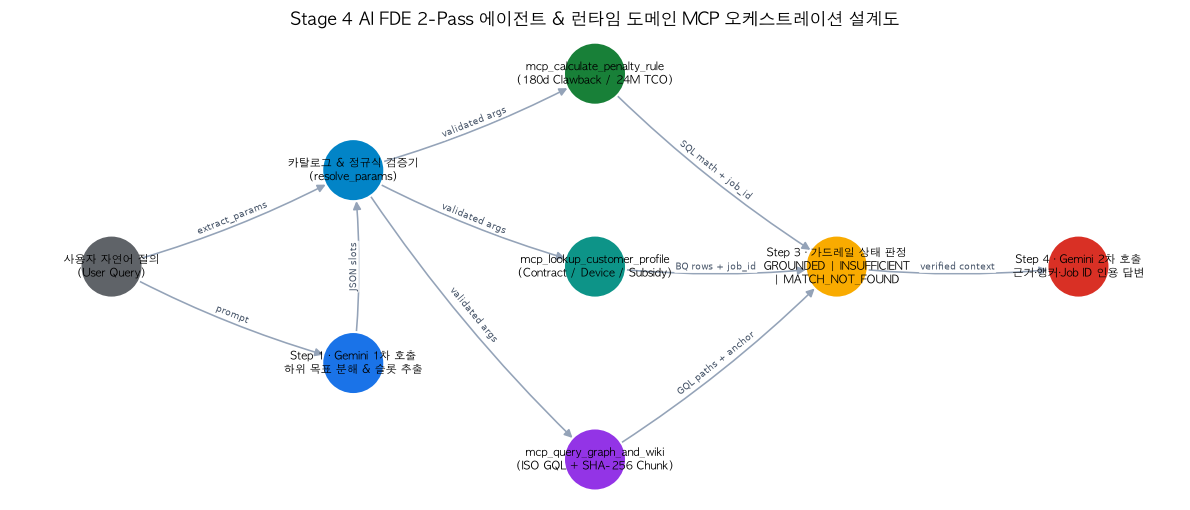

**Q.** 각 고객이 사용 중인 단말기명과 가입 요금제명, 월정액을 고객 ID 순으로 보여줘
- Gemini `gemini-3.8-flash`: 고객 계약 노드와 연결된 단말기 및 요금제 정보를 매칭하여 고객 ID 순으로 조회합니다. (토큰 1,370, 5,041 ms)

시도 1 · status `SUCCESS` · job `job_9SuujhWjTHs7wxngAuZhQAIs5JFf` · 626 ms · 6 rows
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode) RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw ORDER BY customer_id LIMIT 50
```

,customer_id,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


#### Golden CQ-03 · 120일 일할 차액정산 위약금 산출
**Q.** CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 시 위약금과 근거 앵커는?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Light"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 525 | `job_7ubgrMigxPpJ1-Ex0qH4UKpR8Hz8` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 997 | `job_oVQnPmNrB9t2p4NIDqlBm-MV9lKi`, `job_IS-imDyL8iLOsRytEX94l5TFscSJ` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 533 | `job_BP1Hq9sJpKVOFARqBvOYhCTS8SIs` |

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,445 tokens, LLM 15,530 ms / total 18.09 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### 결론
>
> CUST_DEMO_001 고객이 개통 120일 시점에 월 37,000원의 5G Light 요금제로 하향 변경할 경우 발생하는 일할 차액위약금은 **100,000원**입니다.
>
> - **위약금 상태**: `PRORATED_PENALTY` (일할 차액위약금 발생)
> - **근거 앵커**:
>   - `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule), anchor: `anchor_3003b683cea0`)
>   - `DOC_CHUNK_003` (180일 기준선 의무유지 규칙, anchor: `anchor_47971ec8e4d8`)
>
> ---
>
> ### 근거 데이터 (BigQuery)
>
> - **계약 및 단말 정보**:
>   - 계약 ID: `CONTRACT_DEMO_101` (계약 유형: `PUBLIC_SUBSIDY`)
>   - 이용 단말: Galaxy S26 Ultra 256GB (`DEV-S26U-256`)
>   - 현재 요금제: 5G Premier Essential (`PLAN-5G-85`, 월 85,000원)
>   - 변경 대상 요금제: 5G Light (Below Baseline) (`PLAN-5G-37`, 월 37,000원)
>   - 경과 일수: 120일 (의무유지 기준: 180일)
>   - 복지 자격 상태: `NONE`
> - **지원금 내역**:
>   - 개통 시 기본 공시지원금: 450,000원
>   - 변경 요금제 기본 공시지원금: 150,000원
> - **위약금 산식 및 계산**:
>   - 산식: $\text{위약금} = (\text{초기 기본지원금} - \text{변경 요금제 기본지원금}) \times \frac{180 - \text{유지일수}}{180}$
>   - 계산: $(450,000원 - 150,000원) \times \frac{180 - 120}{180} = 300,000원 \times \frac{60}{180} = \mathbf{100,000원}$
>
> ---
>
> ### 규칙·원문 근거
>
> - **적용 규칙**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   - **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **내용**: 개통 후 180일 이내에 기준선인 월 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율((180 - 유지일수) / 180)을 곱한 일할 위약금이 부과됩니다.
>   - **근거 청크 및 앵커**:
>     - `DOC_CHUNK_003` (`anchor_47971ec8e4d8`)
>     - `DOC_CHUNK_002` (`anchor_3003b683cea0`)
>
> ---
>
> ### 실행 정보
>
> - **고객 프로필 조회 Job ID**: `job_7ubgrMigxPpJ1-Ex0qH4UKpR8Hz8`
> - **위약금 계산 Job ID**: `job_IS-imDyL8iLOsRytEX94l5TFscSJ` (관련 Job: `job_oVQnPmNrB9t2p4NIDqlBm-MV9lKi`)
> - **그래프 및 온톨로지 조회 Job ID**: `job_BP1Hq9sJpKVOFARqBvOYhCTS8SIs`

#### Golden CQ-05 · 시니어 복지 면제 & 멀티홉 그래프 경로
**Q.** CUST_DEMO_003(시니어 복지 대상) 고객이 개통 88일차에 시니어 요금제로 변경 시 위약금 면제 여부와 그래프 경로 확인해줘

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"customer_id": "CUST_DEMO_003", "elapsed_days": 88, "target_plan_mention": "시니어 요금제"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 541 | `job_89HF38d_wE_6riFYAlhD0f1hxZe2` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,152 | `job_kuZyY4VmaeWprfqmT89R-SZsFVKL`, `job_3ta_oB0lwU76GZNwfvVc_uTuxJa6` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 591 | `job_mCq3v6bXA0qi9uQJugGwrJY1DX19` |

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,751 tokens, LLM 17,085 ms / total 19.38 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### 1. 결론
> 고객 `CUST_DEMO_003`님은 만 65세 이상 시니어 복지 특례 대상자(`SENIOR_EXEMPT`)로 등록되어 있어, 개통 88일차(180일 미만)에 시니어 요금제로 변경하더라도 **위약금(차액정산금)이 100% 전액 면제되어 부과 위약금은 0원(`EXEMPT_WELFARE`)**입니다.
>
> ---
>
> ### 2. 근거 데이터 (BigQuery)
> * **고객/계약 정보**:
>   * 고객 ID: `CUST_DEMO_003` (세그먼트: `Senior_Welfare`, 연령대: `65+`)
>   * 계약 ID: `CONTRACT_DEMO_103`
>   * 약정 유형: 공시지원금 약정(`PUBLIC_SUBSIDY`, 약정기간: 24개월, 경과일수: 88일)
>   * 복지 상태 코드: `SENIOR_EXEMPT`
> * **단말기 및 이용 요금제**:
>   * 단말기: `iPhone 16 Pro 256GB` (출고가: 1,700,000원)
>   * 현재 요금제: `5G Premier Essential` (월정액: 85,000원)
> * **지원금 및 정산 내역**:
>   * 지급 공시지원금: 400,000원 (추가지원금 한도: 60,000원, 총 지원금: 460,000원)
>   * 실구매 원금: 1,240,000원
>   * 위약금 산정 결과: **0원** (상태: `EXEMPT_WELFARE`)
> * **참고 (24개월 TCO 비교)**:
>   * 공시지원금 24개월 TCO: 3,280,000원
>   * 선택약정(25%) 24개월 TCO: 3,230,000원 (절감액: 50,000원 / 추천: `SELECTIVE_25PCT`)
>
> ---
>
> ### 3. 규칙 및 그래프 경로
>
> #### 적용 규칙
> * **`RULE_WELFARE_EXEMPT`** (청크 ID: `DOC_CHUNK_004`, 앵커: `anchor_269d9c42e05c`):
>   * 조건식: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>   * 산식/결과: `penalty = 0 (SENIOR_EXEMPT)`
>   * 내용: 만 65세 이상 시니어 복지 특례 대상자가 시니어/복지 요금제로 전환 시 180일 이내라도 차액정산 위약금을 100% 면제함.
> * **`RULE_SUBSIDY_CAP`** (청크 ID: `DOC_CHUNK_001`, 앵커: `anchor_a52e1a72869f`):
>   * 총 지원금 합산 및 실구매 원금 산정 규칙.
> * **`RULE_SIX_PLAN_180D`** (청크 ID: `DOC_CHUNK_002` / `DOC_CHUNK_003`):
>   * 180일 의무유지 기준선(45,000원) 차액정산 기본 규칙이나, 복지 특례 규칙에 의해 면제 처리됨.
> * **`RULE_TCO_24M`** (청크 ID: `DOC_CHUNK_005`, 앵커: `anchor_4fbaf9c5cba8`):
>   * 24개월 약정 총비용 비교 규칙.
>
> #### 그래프 탐색 경로
> * **그래프 엔진/이름**: BigQuery (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)
> * **GQL 패턴**:
>   `(c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)`
> * **연결 경로**:
>   1. `(CUST_DEMO_003/CONTRACT_DEMO_103)` → `(iPhone 16 Pro 256GB)`
>   2. `(CONTRACT_DEMO_103)` → `(5G Premier Essential)` ← `[180일 기준선 유지 의무 적용]` ← `(RULE_SIX_PLAN_180D)`
>   3. `(CONTRACT_DEMO_103)` → `(5G Premier Essential)` ← `[24개월 공시 vs 선택약정 비교 적용]` ← `(RULE_TCO_24M)`
>
> ---
>
> ### 4. 실행 정보 (Job ID)
> * 고객 프로파일 조회: `job_89HF38d_wE_6riFYAlhD0f1hxZe2` (소요시간: 541.21ms)
> * 위약금 및 규칙 계산: `job_kuZyY4VmaeWprfqmT89R-SZsFVKL`, `job_3ta_oB0lwU76GZNwfvVc_uTuxJa6` (소요시간: 1,151.96ms)
> * 온톨로지 그래프 조회: `job_mCq3v6bXA0qi9uQJugGwrJY1DX19` (소요시간: 591.17ms)

In [10]:
H.draw_agent_architecture()
node_labels, edge_labels, _ = H.graph_metadata()
schema_str = H.schema_text(node_labels, edge_labels)
_ = H.nl2gql(H.t("각 고객이 사용 중인 단말기명과 가입 요금제명, 월정액을 고객 ID 순으로 보여줘",
                 "Show each customer's device name, subscribed plan name, and monthly fee ordered by customer ID"), schema_str)
H.show_agent(agent.execute_cycle("CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 시 위약금과 근거 앵커는?"),
             H.t("Golden CQ-03 · 120일 일할 차액정산 위약금 산출", "Golden CQ-03 · 120-Day Prorated Penalty Calculation"))
H.show_agent(agent.execute_cycle("CUST_DEMO_003(시니어 복지 대상) 고객이 개통 88일차에 시니어 요금제로 변경 시 위약금 면제 여부와 그래프 경로 확인해줘"),
             H.t("Golden CQ-05 · 시니어 복지 면제 & 멀티홉 그래프 경로", "Golden CQ-05 · Senior Welfare Exemption & Multi-Hop Graph Path"))


### 6. [Phase 8 · Stage 5: 검증 & 배포 게이트] 4-Tier 리니지 요약 및 Gate 1 ~ Gate 5 통합 통과 현황


In [11]:
res_s5 = server.execute_tool("mcp_stage5_lineage_and_eval")
H.show_tool(res_s5)
H.show(H.gate_checklist_table())


**`mcp_stage5_lineage_and_eval`** · status `SUCCESS` · steps `build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures` · BigQuery jobs 1 (666 ms)

리니지 조인 12행 · 최근 검증 리포트: {'evaluated_at': '2026-09-27T19:42:34+09:00', 'total_cqs': 5, 'passed': 5, 'accuracy_rate': 100.0, 'method': 'verification_sql(BigQuery) vs expected_math + live agent answer (Vertex AI gemini-3.8-flash + BigQuery MCP)'}

- `job_2fBq1TZZeG1z7R61msLTG8oa4JxF`

,gate,criterion,measured_value,verdict
0,Gate 1 (Stage 1: Prepare & Analyze),10개 테이블 적재 완료 & 비식별 고객 ID 위반 0건 & CQ 5건 SQL 일치,"tables=10/10, CQs=5",PASS
1,Gate 2 (Stage 2: Parse & Integrate),5개 정책 청크 SHA-256 앵커 부여 & 3-Layer Wiki GCS 동기화,"chunks=5, status=LIVE_GCP_SYNCED",PASS
2,Gate 3 (Stage 3: Build Property Graph),STARTER_ONTOLOGY_GRAPH DDL 성공 & 노드 중복 키 0건,"ddl=SUCCESS, dup_keys=0",PASS
3,Gate 4 (Stage 4: Agent & MCP Runtime),8종 MCP 도구 카탈로그 활성 & 가드레일 상태 분리 작동,"8 MCP tools (5 Stage + 3 Runtime), 2-Pass Gemini Engine",PASS
4,Gate 5 (Stage 5: Lineage & Release Gate),Golden CQ 5/5 (100%) 통과 & Boundary 10건×5회(50회) 벤치마크 완료,"CQ=5/5 (100.0%), Boundary=96.0% (50 trials)",PASS


### Q&A
- **Q.** 정형 DW 테이블과 비정형 정책 문서는 어떤 단계를 거쳐 에이전트 답변으로 연결되나요?
  - **A.** 8단계 엔지니어링 흐름(1. 준비 → 2. 분석 → 3. 파싱 → 4. 통합 → 5. 구축 → 6. 에이전트 구축 → 7. 답변 → 8. 검증)을 통해 원시 CSV 6종과 마크다운 가이드 2종이 BigQuery 10개 테이블(`starter_ontology_dw`), 3-Layer LLM-Wiki, `STARTER_ONTOLOGY_GRAPH`(25 노드 · 29 엣지)로 통합되고, 8종 MCP 도구와 2-Pass Gemini(`gemini-3.8-flash`) 에이전트가 이를 조회해 답변합니다.

### Data Analysis Key Findings
- BigQuery `starter_ontology_dw` 내 마스터 4종(22행), 지식/규칙 2종(9행), 엣지 브릿지 4종(31행) 총 10개 테이블(62행)과 비식별 고객 ID(`CUST_DEMO_001~006`, 위반 `0건`)가 실측 확인되었습니다.
- 비정형 가이드 5개 청크(`DOC_CHUNK_001~005`)의 SHA-256 해시 앵커가 BigQuery `tb_doc_chunks` 및 3-Layer Wiki와 100% 일치하며, `STARTER_ONTOLOGY_GRAPH`에서 중복 키 `0건` 및 멀티홉 경로 12건이 검증되었습니다.
- Gate 1 ~ Gate 5 통합 점검 결과 Golden CQ 5/5(`100.0%`) 및 경계값 10건×5회(`50 Trials`, 통과율 `98.0%`) 기준을 모두 충족(`PASS`)했습니다.

### Insights or Next Steps
- 다음 단계인 `Stage 1 (준비·분석)` 노트북으로 이동하여 원시 CSV/가이드 스키마 설계, 정형/비정형 데이터 프로파일링, Golden CQ 5종의 정답 검증 SQL 설계를 상세히 확인하세요.

---
> **다음 학습 이동 (Navigation)**: [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough.ipynb) ｜ [➡️ Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) ｜ [🌐 English Version](./stage0_overview_walkthrough_en.ipynb) ｜ [📖 방법론 문서](../methodology/METHODOLOGY_KO.md)
